# Chapter 4 Problems

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (6, 1.6)},
)
%config InlineBackend.figure_format = "retina"

<Figure size 640x480 with 0 Axes>

In [4]:
# Simplified int and float __repr__
np.set_printoptions(legacy='1.25')

In [5]:
# Download datasets/ directory if necessary
from ministats import ensure_datasets
ensure_datasets()

Found ../datasets/ and copied files to datasets/.


$\def\stderr#1{\mathbf{se}_{#1}}$
$\def\stderrhat#1{\hat{\mathbf{se}}_{#1}}$
$\def\Mean{\textbf{mean}}$
$\def\Var{\textbf{var}}$
$\def\Std{\textbf{std}}$
$\def\Freq{\textbf{freq}}$
$\def\RelFreq{\textbf{relfreq}}$
$\def\CI#1{\textbf{CI}_{#1}}$
$\def\CIL#1{\textbf{L}_{#1}}$
$\def\CIU#1{\textbf{U}_{#1}}$
$\def\ci#1{\textbf{ci}_{#1}}$
$\def\cil#1{\textbf{l}_{#1}}$
$\def\ciu#1{\textbf{u}_{#1}}$
$\def\DMeans{\textbf{dmeans}}$
$\def\Prop{\textbf{prop}}$
$\def\DProps{\textbf{dprops}}$
$\def\Err{ {\Large \varepsilon}}$
$\def\calN{\mathcal{N}}$
$\def\Tdist{\mathcal{T}}$
$\def\Expon{\mathrm{Expon}}$

(this cell contains the macro definitions like $\stderr{\overline{\mathbf{x}}}$, $\stderrhat{}$, $\Mean$, ...)

### Problem 4.XX

Investigate sensitivity of $F$-test for the model
lmlong $y \sim x_1 + x_2 + x_3 + \mathcal{N}(0,1)$,
versus the model \tt{lmshort} $y \sim x1 + x2 + \mathcal{N}(0,1)$ 
where each x1 x2 and x3 are $\mathcal{N}(0,1)$.
How big does alpha have to be for \tt{compare\_f\_test} to be significant?

In [4]:
np.random.seed(42)
n = 100
x1s = norm(0,1).rvs(n)
x2s = norm(0,1).rvs(n)
x3s = norm(0,1).rvs(n)

alpha = 0.138702
ys = x1s + x2s + alpha*x3s + norm(0,1).rvs(n)

df_x1x2x3y = pd.DataFrame({"x1":x1s, "x2":x2s, "x3":x3s, "y":ys})

lm_long = smf.ols("y ~ + 1 + x1 + x2 + x3", data=df_x1x2x3y).fit()
lm_short = smf.ols("y ~ + 1 + x1 + x2", data=df_x1x2x3y).fit()
lm_long.compare_f_test(lm_short)

(3.9402479702448003, 0.04999757068441112, 1.0)

### P4.??

<!-- {??} -->

Failure cases

In [6]:
n = 30
# Generate the random observations from the predictor
from scipy.stats import uniform
np.random.seed(48)
xs = uniform(0,10).rvs(n)

#### a) Normal noise

In [7]:
np.random.seed(49)

# Generate the random observations from normal noise
from scipy.stats import norm
errs = norm(0,1).rvs(n)

# Generate the observations from the outcome variable
ys_a = 7 + 5*xs + errs

# Package xs, ys_a as a DataFrame
df_a = pd.DataFrame({"x":xs, "y":ys_a})

Intercept    7.170496
x            4.973410
dtype: float64
                  0         1
Intercept  6.589894  7.751098
x          4.850163  5.096657


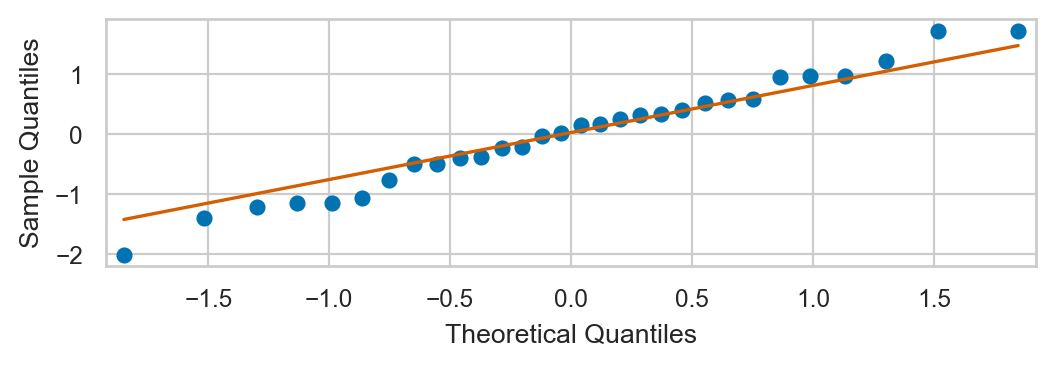

In [9]:
# Fit linear model
import statsmodels.formula.api as smf
lm_a = smf.ols("y ~ 1 + x", data=df_a).fit()

# Print the parameter estimates
print(lm_a.params)

# Print 90% confidence intervals for the parameters
print(lm_a.conf_int(alpha=0.1))

# Generate a Q-Q plot of the residuals
from statsmodels.graphics.api import qqplot 
qqplot(lm_a.resid , line="q");

#### b) Exponential noise


                  0         1
Intercept  8.243569  9.846090
x          4.704619  5.044794


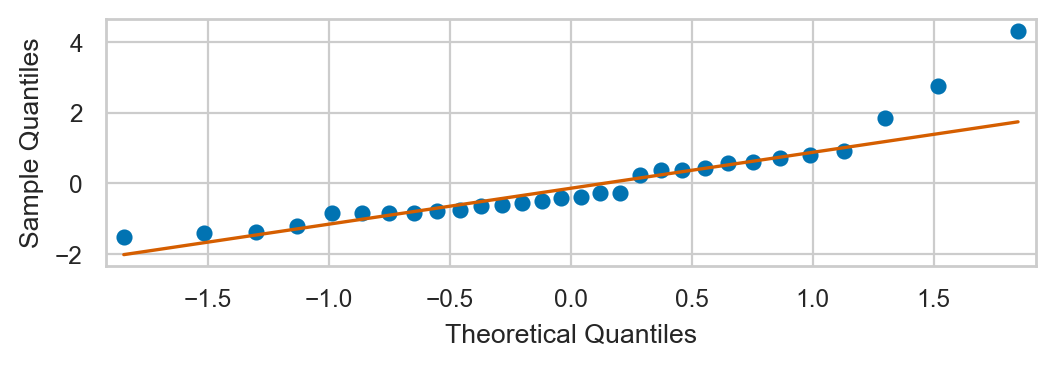

In [10]:
np.random.seed(51)
from scipy.stats import expon
errs2 = expon(scale=2).rvs(n)

# Combine to obtain observations from the outcome variable
beta0, beta1 = 7, 5
ys_b = beta0 + beta1*xs + errs2

# Package xs and ys_b as a DataFrame
df_b = pd.DataFrame({"x":xs, "y":ys_b})

# Fit linear model
import statsmodels.formula.api as smf
lm_b = smf.ols("y ~ 1 + x", data=df_b).fit()

# Print the confidence interval for the parameters
print(lm_b.conf_int(alpha=0.1))

# Q-Q plot of the residuals
from statsmodels.graphics.api import qqplot 
qqplot(lm_b.resid , line="q");

#### c) Nonlinearity


Intercept    3.996934
x            6.746238
dtype: float64
                  0         1
Intercept  3.086272  4.907596
x          6.552928  6.939549


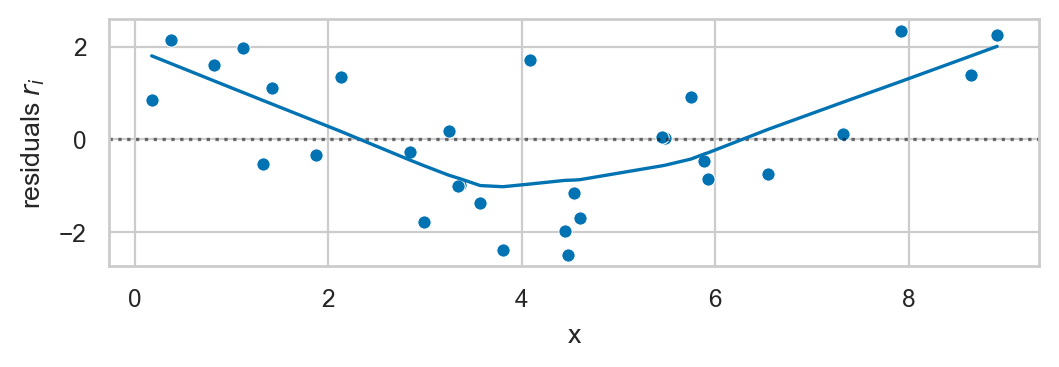

In [11]:
# Set the random seed to a particular value to get a reproducible result
# Generate the random observations from X1, X2, and the noise
np.random.seed(54)
from scipy.stats import norm
errs = norm(0,1).rvs(n)

# Generate the observations from the outcome variable
beta0, beta1 = 7, 5
ys_c = beta0 + beta1*xs + 0.2*xs**2 + errs

# Package xs, ys as a pd.DataFrame
df_c = pd.DataFrame({"x":xs, "y":ys_c})

# Fit linear model
import statsmodels.formula.api as smf
lm_c = smf.ols("y ~ 1 + x", data=df_c).fit()

# Show the parameter estimates
print(lm_c.params)
print(lm_c.conf_int(alpha=0.1))

# from statsmodels.graphics.api import qqplot 
# qqplot(lm_c.resid , line="q");

from ministats import plot_resid
plot_resid(lm_c, pred="x", lowess=True);

#### d) Heteroscedasticity


Intercept    8.171594
x            4.384377
dtype: float64
                  0          1
Intercept  5.257172  11.086015
x          3.765718   5.003035


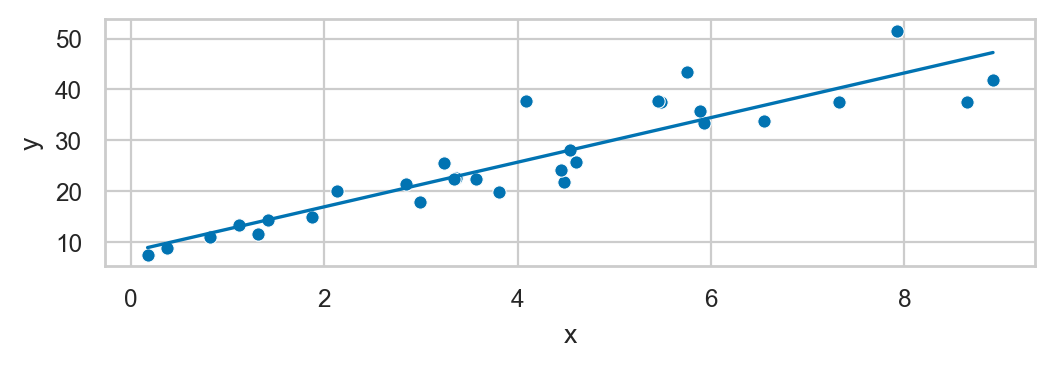

In [12]:
np.random.seed(54)

# Generate the noise whose scale depends on the predictor
from scipy.stats import norm
zs = norm(0,1).rvs(n)
errs3 = xs * zs

# Generate the observations from the outcome variable
beta0, beta1 = 7, 5
ys_d = beta0 + beta1*xs + errs3

# Package x1s, x2s, and ys as a pd.DataFrame
df_d = pd.DataFrame({"x":xs, "y":ys_d})
df_d.head(3)

# Fit linear model
import statsmodels.formula.api as smf
lm_d = smf.ols("y ~ 1 + x", data=df_d).fit()

# Show the parameter estimates
print(lm_d.params)
print(lm_d.conf_int(alpha=0.1))


from ministats import plot_reg
plot_reg(lm_d);

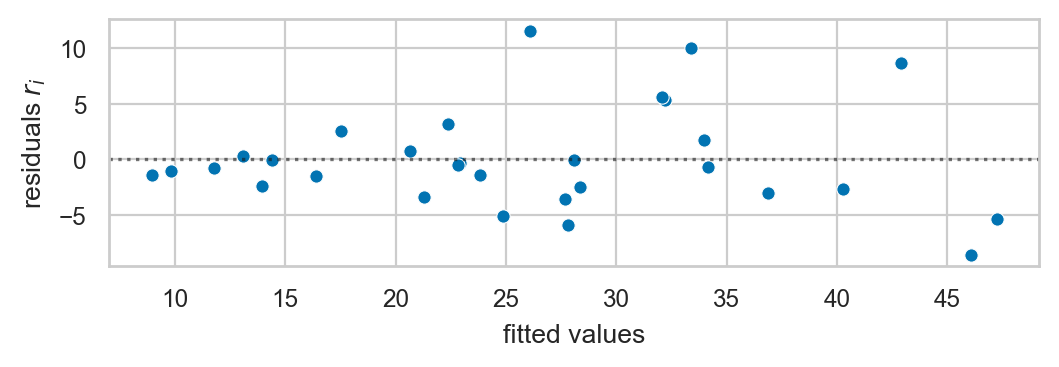

In [13]:
from ministats import plot_resid
plot_resid(lm_d);

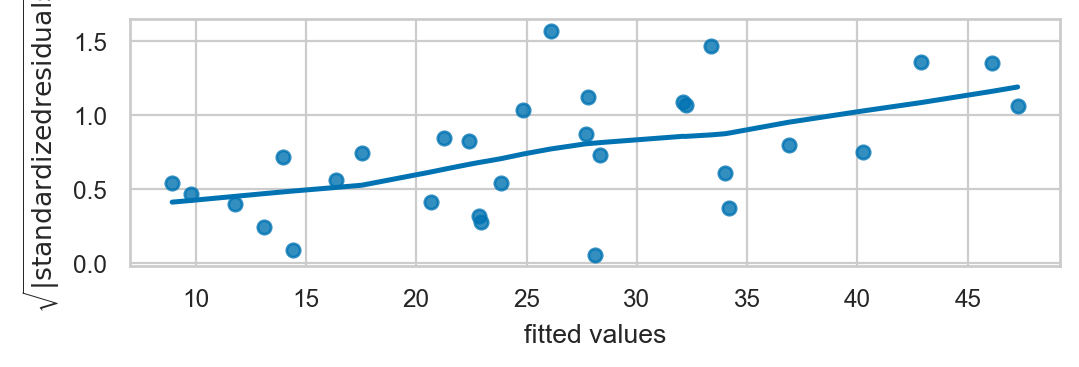

In [14]:
from ministats import plot_scaleloc
plot_scaleloc(lm_d);